# Task 2: Restaurant Recommendation System (Content-Based)
**Cognifyz Technologies - Machine Learning Internship**
**Intern:** Manish Chandra Raturi
**Dataset:** Restaurant dataset (`Dataset.csv`, 9,551 restaurants, 21 columns)

**Objective:** Recommend restaurants that match a user's preferences (cuisine, price range, city, quality).

**Steps:** (1) Preprocess, (2) Define recommendation criteria, (3) Content-based filtering, (4) Test with sample users and evaluate.

## 1. Setup and load data

In [1]:
import warnings, difflib
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30, "display.width", 170, "display.max_colwidth", 45)
df = pd.read_csv("Dataset.csv", encoding="utf-8-sig")
print("Shape:", df.shape)
print("Missing Cuisines:", df["Cuisines"].isna().sum())

Shape: (9551, 21)
Missing Cuisines: 9


## 2. Preprocessing
- Missing `Cuisines` -> `"Unknown"` (kept, but never recommended on cuisine match).
- `Cuisines` is a comma-separated list, so each restaurant becomes a **multi-label (multi-hot) vector** over all cuisines. Names are lower-cased and stripped so `"North Indian"` and `"north indian "` match.
- Categorical flags (`Yes`/`No`) -> 1/0. `City` is lower-cased for matching.
- `Price range` (1-4) is used for price, **not** `Average Cost for two` (that column mixes currencies).
- Restaurants with rating 0 are *unrated*, so they are excluded from recommendations. A minimum vote count also avoids recommending a restaurant with a perfect score from 2 votes.

In [2]:
df["Cuisines"] = df["Cuisines"].fillna("Unknown")
df["cuisine_list"] = df["Cuisines"].apply(lambda s: sorted({c.strip().lower() for c in s.split(",")}))
df["city_key"] = df["City"].str.strip().str.lower()
df["table_booking"] = (df["Has Table booking"] == "Yes").astype(int)
df["online_delivery"] = (df["Has Online delivery"] == "Yes").astype(int)
df = df.reset_index(drop=True)

mlb = MultiLabelBinarizer()
CUISINE_MATRIX = mlb.fit_transform(df["cuisine_list"]).astype(np.float32)   # n_restaurants x n_cuisines
CUISINES = list(mlb.classes_)
CUISINE_INDEX = {c: i for i, c in enumerate(CUISINES)}
print("Restaurants:", CUISINE_MATRIX.shape[0], "| distinct cuisines:", len(CUISINES))
print("Top cuisines:", df["Cuisines"].str.split(",").explode().str.strip().value_counts().head(10).to_dict())

Restaurants: 9551 | distinct cuisines: 146
Top cuisines: {'North Indian': 3960, 'Chinese': 2735, 'Fast Food': 1986, 'Mughlai': 995, 'Italian': 764, 'Bakery': 745, 'Continental': 736, 'Cafe': 703, 'Desserts': 653, 'South Indian': 636}


## 3. Recommendation criteria and scoring
**Hard filters** (a restaurant is removed if it fails): city, price range (within `price_flex` of the target), minimum rating, minimum votes, online delivery, table booking.

**Soft score** for every remaining restaurant (0 to 1):

`score = 0.65 x cuisine_similarity + 0.20 x rating/5 + 0.15 x price_closeness`

- **cuisine_similarity** = Jaccard similarity between the user's preferred cuisines and the restaurant's cuisines (shared / total distinct). A restaurant with no shared cuisine is never recommended.
- **price_closeness** = `1 - |price_range - target| / 3`. Only used when a price target is given; otherwise its weight is redistributed.

This is *content-based filtering*: it compares restaurant attributes with the user's stated preferences. No other users' behaviour is involved.

In [3]:
RATED = (df["Aggregate rating"] > 0).values
W_CUISINE, W_RATING, W_PRICE = 0.65, 0.20, 0.15


def _suggest(value, options):
    return difflib.get_close_matches(value, options, n=3, cutoff=0.6)


def recommend(cuisines, city=None, price_range=None, price_flex=0, min_rating=0.0, min_votes=10,
              online_delivery=None, table_booking=None, top_n=10):
    """Content-based restaurant recommendations.

    cuisines        : list of preferred cuisines, e.g. ["North Indian", "Chinese"]
    city            : city name (optional hard filter)
    price_range     : target price range 1-4 (optional)
    price_flex      : how far from the target price range is still allowed (0 = exact)
    min_rating      : minimum aggregate rating
    min_votes       : minimum votes (guards against tiny-sample ratings)
    online_delivery / table_booking : True / False / None (no preference)
    """
    # ---- validate input
    prefs = [c.strip().lower() for c in cuisines]
    bad = [c for c in prefs if c not in CUISINE_INDEX]
    if bad:
        hints = {b: _suggest(b, CUISINES) for b in bad}
        raise ValueError(f"Unknown cuisine(s): {hints if any(hints.values()) else bad}. See CUISINES for valid names.")
    if city is not None and city.strip().lower() not in set(df["city_key"]):
        raise ValueError(f"Unknown city '{city}'. Did you mean: {_suggest(city.strip().lower(), sorted(set(df['city_key'])))}?")
    if price_range is not None and price_range not in (1, 2, 3, 4):
        raise ValueError("price_range must be 1, 2, 3 or 4")

    # ---- hard filters
    mask = RATED & (df["Votes"].values >= min_votes) & (df["Aggregate rating"].values >= min_rating)
    if city is not None:
        mask &= (df["city_key"].values == city.strip().lower())
    if price_range is not None:
        mask &= (np.abs(df["Price range"].values - price_range) <= price_flex)
    if online_delivery is not None:
        mask &= (df["online_delivery"].values == int(online_delivery))
    if table_booking is not None:
        mask &= (df["table_booking"].values == int(table_booking))

    # ---- cuisine similarity (Jaccard)
    u = np.zeros(len(CUISINES), dtype=np.float32)
    for c in prefs:
        u[CUISINE_INDEX[c]] = 1.0
    shared = CUISINE_MATRIX @ u
    union = CUISINE_MATRIX.sum(axis=1) + u.sum() - shared
    cuisine_sim = np.divide(shared, union, out=np.zeros_like(shared), where=union > 0)
    mask &= cuisine_sim > 0                      # must share at least one cuisine

    if mask.sum() == 0:
        return pd.DataFrame(columns=["Restaurant Name", "City", "Locality", "Cuisines", "Price range",
                                     "Aggregate rating", "Votes", "score"])

    # ---- score
    w_c, w_r = W_CUISINE, W_RATING
    w_p = W_PRICE if price_range is not None else 0.0
    total = w_c + w_r + w_p
    price_close = 1 - np.abs(df["Price range"].values - (price_range or 0)) / 3 if price_range is not None else 0
    score = (w_c * cuisine_sim + w_r * df["Aggregate rating"].values / 5 + w_p * price_close) / total

    out = df.loc[mask, ["Restaurant Name", "City", "Locality", "Cuisines", "Price range", "Aggregate rating", "Votes"]].copy()
    out["score"] = score[mask].round(3)
    return out.sort_values(["score", "Aggregate rating", "Votes"], ascending=False).head(top_n).reset_index(drop=True)


def similar_to(name, city=None, top_n=10, exclude_same_name=True, min_votes=10):
    """'More like this': recommend restaurants similar to a restaurant the user already likes."""
    hits = df[df["Restaurant Name"].str.lower() == name.strip().lower()]
    if city:
        hits = hits[hits["city_key"] == city.strip().lower()]
    if hits.empty:
        raise ValueError(f"Restaurant '{name}' not found. Close matches: {_suggest(name.lower(), sorted(df['Restaurant Name'].str.lower().unique()))}")
    ref = hits.sort_values("Votes", ascending=False).iloc[0]
    print(f"Reference: {ref['Restaurant Name']} | {ref['City']} | {ref['Cuisines']} | price range {ref['Price range']} | rating {ref['Aggregate rating']}")
    res = recommend(ref["cuisine_list"], city=ref["City"], price_range=int(ref["Price range"]), price_flex=1,
                    min_votes=min_votes, top_n=top_n + 30)
    if exclude_same_name:
        res = res[res["Restaurant Name"].str.lower() != ref["Restaurant Name"].lower()]
    return res.head(top_n).reset_index(drop=True)

print("Functions ready.")

Functions ready.


## 4. Test the system with sample users
Six different user profiles, including a strict one, a loose one and a "more like this" request.

In [4]:
print("USER 1: loves North Indian + Mughlai food, New Delhi, mid-range (price 2), at least 4.0 rating")
display(recommend(["North Indian", "Mughlai"], city="New Delhi", price_range=2, min_rating=4.0, top_n=8))

USER 1: loves North Indian + Mughlai food, New Delhi, mid-range (price 2), at least 4.0 rating


,Restaurant Name,City,Locality,Cuisines,Price range,Aggregate rating,Votes,score
0,Dilli BC,New Delhi,Malviya Nagar,"North Indian, Mughlai",2,4.4,84,0.976
1,The Last Mughal (TLM),New Delhi,Shahpur Jat,"North Indian, Mughlai",2,4.4,52,0.976
2,Shikhara,New Delhi,Greater Kailash (GK) 1,"North Indian, Mughlai",2,4.2,237,0.968
3,Indian Saffron Co.,New Delhi,Vasant Kunj,"North Indian, Mughlai",2,4.2,62,0.968
4,Dilli BC,New Delhi,Greater Kailash (GK) 2,"North Indian, Mughlai",2,4.1,267,0.964
5,Karim's,New Delhi,Jama Masjid,"Mughlai, North Indian",2,4.0,4689,0.960
6,Rajinder Da Dhaba,New Delhi,Safdarjung,"North Indian, Mughlai, Chinese",2,4.3,3530,0.755
7,London Street Kitchen,New Delhi,Rajinder Nagar,"North Indian, Mughlai, Chinese",2,4.2,163,0.751


In [5]:
print("USER 2: wants Italian or Pizza, Gurgaon, price range around 2 (1 to 3 allowed), needs online delivery")
display(recommend(["Italian", "Pizza"], city="Gurgaon", price_range=2, price_flex=1, online_delivery=True, top_n=8))

USER 2: wants Italian or Pizza, Gurgaon, price range around 2 (1 to 3 allowed), needs online delivery


,Restaurant Name,City,Locality,Cuisines,Price range,Aggregate rating,Votes,score
0,Crust Bistro,Gurgaon,"Huda City Centre Metro Station, Sector 29...","Italian, Pizza",2,3.6,144,0.944
1,La Pino'z Pizza,Gurgaon,Sector 31,"Pizza, Italian",2,3.5,22,0.940
2,Baking Bad,Gurgaon,DLF Phase 4,"Italian, Pizza",3,3.7,98,0.898
3,Fat Lulu's,Gurgaon,Sohna Road,"Pizza, Italian",3,3.7,21,0.898
4,Pizza Central,Gurgaon,DLF Phase 4,"Fast Food, Italian, Pizza",2,4.1,151,0.747
5,PizzaVito,Gurgaon,"Central Plaza Mall, Golf Course Road","Italian, Pizza, Lebanese",2,3.3,218,0.715
6,Pizza Hut Delivery,Gurgaon,"DLF Mega Mall, DLF Phase 1","Italian, Pizza, Fast Food",2,2.8,29,0.695
7,Pizza Hut Delivery,Gurgaon,Sector 23,"Italian, Pizza, Fast Food",2,2.7,53,0.691


In [6]:
print("USER 3: upscale Chinese, Noida, price range around 3 (2 to 4 allowed), table booking required, rating >= 3.5")
display(recommend(["Chinese"], city="Noida", price_range=3, price_flex=1, table_booking=True, min_rating=3.5, top_n=8))

USER 3: upscale Chinese, Noida, price range around 3 (2 to 4 allowed), table booking required, rating >= 3.5


,Restaurant Name,City,Locality,Cuisines,Price range,Aggregate rating,Votes,score
0,Mainland China,Noida,Sector 18,Chinese,3,3.7,743,0.948
1,Mandarin Trail,Noida,"The Great India Place, Sector 38",Chinese,3,3.7,517,0.948
2,Kalpak Restaurant & Cafe,Noida,Sector 50,"North Indian, Chinese",3,4.3,150,0.647
3,The Punjabiis Restro Bar,Noida,"The Great India Place, Sector 38","North Indian, Chinese",3,4.0,395,0.635
4,Crazy Noodles,Noida,"The Great India Place, Sector 38","Chinese, Thai",3,3.6,507,0.619
5,The Saffron Boutique,Noida,Sector 110,"North Indian, Chinese",2,4.0,175,0.585
6,Mamagoto,Noida,"DLF Mall of India, Sector 18, Noida","Asian, Thai, Chinese",3,4.3,428,0.539
7,Bamboo Shoots,Noida,Sector 18,"Chinese, Seafood, Asian",3,3.9,515,0.523


In [7]:
print("USER 4: cheap fast food (price 1) anywhere, rating >= 3.5, many votes (>= 200)")
display(recommend(["Fast Food"], price_range=1, min_rating=3.5, min_votes=200, top_n=8))

USER 4: cheap fast food (price 1) anywhere, rating >= 3.5, many votes (>= 200)


,Restaurant Name,City,Locality,Cuisines,Price range,Aggregate rating,Votes,score
0,Sagar Gaire Fast Food,Bhopal,Arera Colony,Fast Food,1,4.9,427,0.996
1,Novelty Dairy & Stores,New Delhi,Jangpura,Fast Food,1,4.1,352,0.964
2,RollsKing,Noida,Sector 18,Fast Food,1,4.0,1055,0.960
3,The Rolling Joint,New Delhi,Connaught Place,Fast Food,1,3.9,783,0.956
4,RollsKing,Noida,"DLF Mall of India, Sector 18, Noida",Fast Food,1,3.9,232,0.956
5,RollsKing,Noida,Sector 62,Fast Food,1,3.8,401,0.952
6,Bon App��tit,New Delhi,Janakpuri,Fast Food,1,3.8,212,0.952
7,Depaul's,New Delhi,Janpath,Fast Food,1,3.7,475,0.948


In [8]:
print("USER 5: 'More like this' - likes a specific restaurant")
display(similar_to("Barbeque Nation", city="New Delhi", top_n=8))

USER 5: 'More like this' - likes a specific restaurant
Reference: Barbeque Nation | New Delhi | North Indian, Chinese | price range 3 | rating 4.1


,Restaurant Name,City,Locality,Cuisines,Price range,Aggregate rating,Votes,score
0,Aromas of Pind,New Delhi,Mathura Road,"North Indian, Chinese",3,4.2,278,0.968
1,The Royal Turban,New Delhi,Rajouri Garden,"North Indian, Chinese",3,3.8,608,0.952
2,Bemisaal Reloaded,New Delhi,Janakpuri,"North Indian, Chinese",3,3.8,128,0.952
3,Dhaba,New Delhi,Rajouri Garden,"Chinese, North Indian",3,3.7,662,0.948
4,Pacific Asia,New Delhi,Netaji Subhash Place,"North Indian, Chinese",3,3.7,151,0.948
5,Moti Mahal,New Delhi,Daryaganj,"North Indian, Chinese",3,3.6,711,0.944
6,Invitation,New Delhi,Ashok Vihar Phase 2,"North Indian, Chinese",3,3.6,457,0.944
7,Krips Restaurant,New Delhi,"Basant Lok Market, Vasant Vihar","North Indian, Chinese",3,3.5,193,0.940


In [9]:
print("USER 6: edge cases (should not crash)")
for label, kwargs in {
    "typo in cuisine": dict(cuisines=["North Indain"]),
    "unknown city": dict(cuisines=["Chinese"], city="Atlantis"),
    "impossible combination": dict(cuisines=["Sushi"], city="Faridabad", price_range=4, min_rating=4.5),
}.items():
    try:
        r = recommend(**kwargs)
        print(f"- {label}: returned {len(r)} rows (empty result handled cleanly)")
    except ValueError as e:
        print(f"- {label}: ValueError -> {e}")

USER 6: edge cases (should not crash)
- typo in cuisine: ValueError -> Unknown cuisine(s): {'north indain': ['north indian', 'south indian', 'north eastern']}. See CUISINES for valid names.
- unknown city: ValueError -> Unknown city 'Atlantis'. Did you mean: []?
- impossible combination: returned 0 rows (empty result handled cleanly)


## 5. Evaluate quality
There are **no user histories (clicks, orders) in this dataset**, so a standard accuracy metric (precision against what users actually chose) cannot be computed honestly. Instead three checks are used:
1. **Constraint check:** every recommendation obeys every filter (must be 100%).
2. **Coverage:** how often a realistic request returns a full list.
3. **Quality lift:** recommended restaurants versus a random pick from the *same filtered pool* (same city, price, votes). This shows whether the scoring adds value beyond just filtering.

,value
Simulated users,300
Constraint check passed (city & price),100.0%
Coverage: full 10-item list,94.7%
Avg items returned,9.77
Cuisine match - recommended,100.0%
Cuisine match - random baseline,19.2%
Avg rating - recommended,3.465
Avg rating - random baseline,3.278


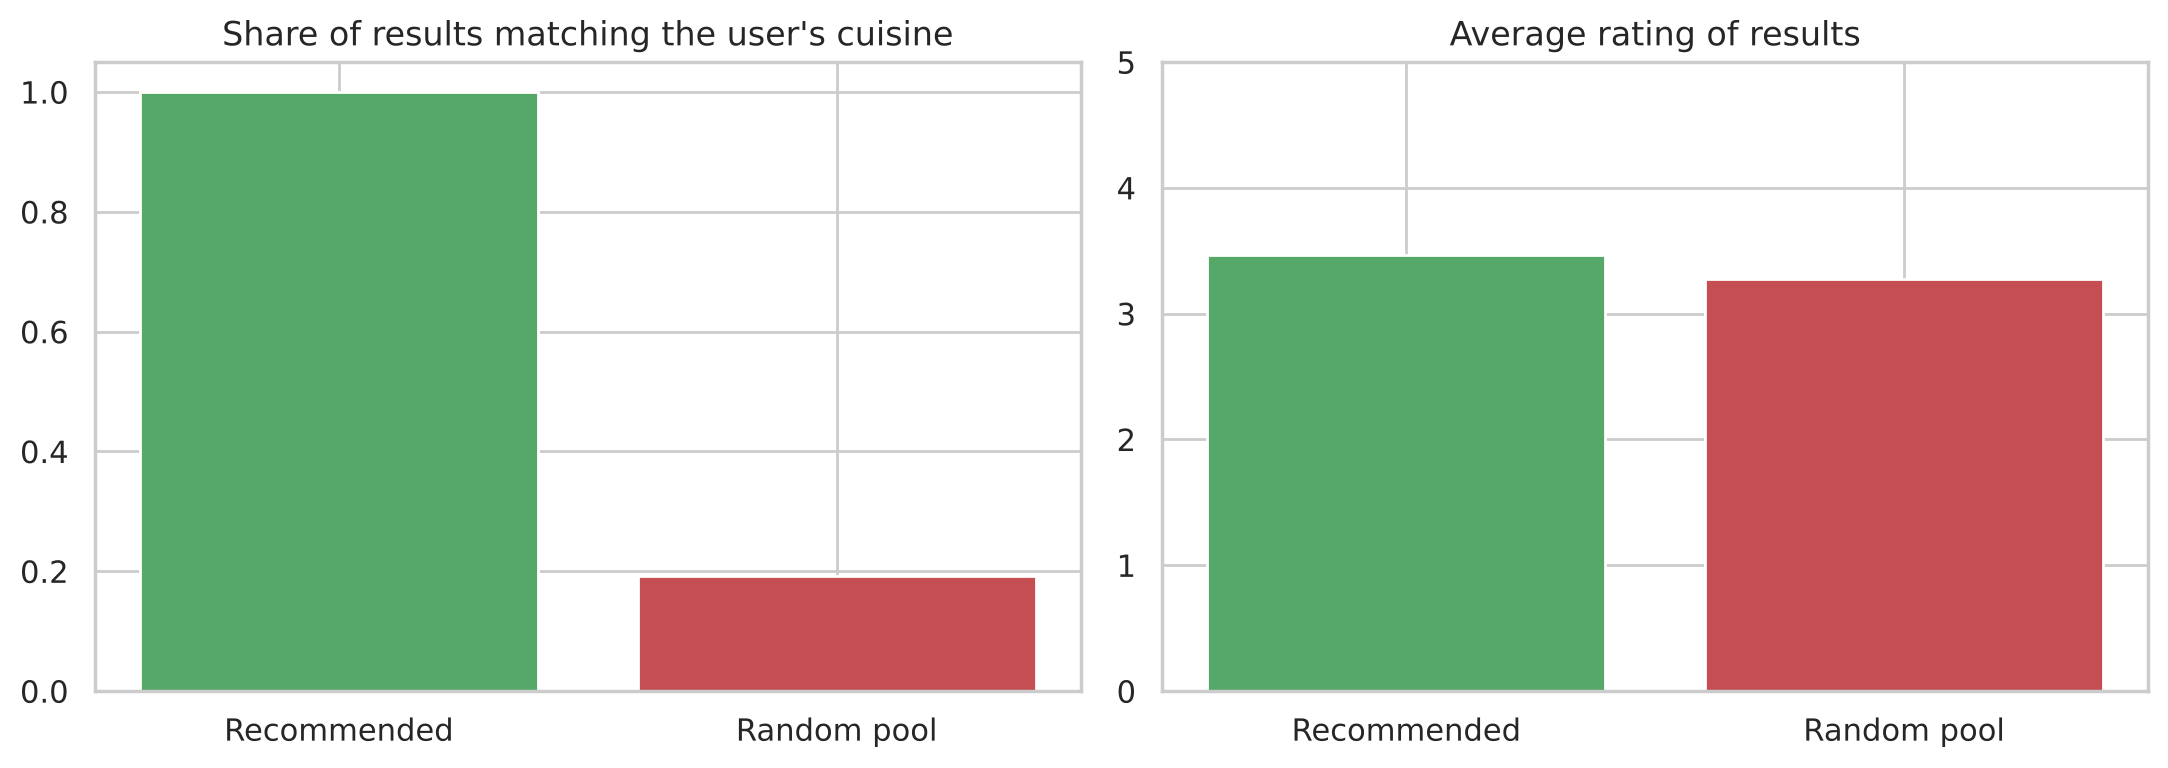

In [10]:
rng = np.random.default_rng(42)
top_cities = df["city_key"].value_counts().head(4).index.tolist()
city_cuisines = {c: df[df.city_key == c]["Cuisines"].str.split(",").explode().str.strip().value_counts() for c in top_cities}

records = []
for i in range(300):
    city = rng.choice(top_cities)
    pool = city_cuisines[city]
    pool = pool[pool >= 20].index.tolist()
    k = int(rng.integers(1, 3))
    cuis = list(rng.choice(pool, size=k, replace=False))
    price = int(rng.integers(1, 4))
    rec = recommend(cuis, city=city, price_range=price, price_flex=1, min_votes=10, top_n=10)
    # baseline: random restaurants from the same filtered pool (city, price, votes) ignoring cuisine and score
    base_mask = (RATED & (df["Votes"].values >= 10) & (df["city_key"].values == city) &
                 (np.abs(df["Price range"].values - price) <= 1))
    base = df[base_mask].sample(min(10, base_mask.sum()), random_state=int(i))
    prefs = {c.lower() for c in cuis}
    records.append({
        "full_list": len(rec) == 10,
        "n_returned": len(rec),
        "price_ok": bool((np.abs(rec["Price range"] - price) <= 1).all()) if len(rec) else True,
        "city_ok": bool((rec["City"].str.lower() == city).all()) if len(rec) else True,
        "cuisine_match_rec": np.mean([bool(prefs & {x.strip().lower() for x in s.split(",")}) for s in rec["Cuisines"]]) if len(rec) else np.nan,
        "cuisine_match_base": np.mean([bool(prefs & {x.strip().lower() for x in s.split(",")}) for s in base["Cuisines"]]),
        "rating_rec": rec["Aggregate rating"].mean() if len(rec) else np.nan,
        "rating_base": base["Aggregate rating"].mean(),
    })
ev = pd.DataFrame(records)
summary = pd.Series({
    "Simulated users": len(ev),
    "Constraint check passed (city & price)": f"{(ev.price_ok & ev.city_ok).mean():.1%}",
    "Coverage: full 10-item list": f"{ev.full_list.mean():.1%}",
    "Avg items returned": round(ev.n_returned.mean(), 2),
    "Cuisine match - recommended": f"{ev.cuisine_match_rec.mean():.1%}",
    "Cuisine match - random baseline": f"{ev.cuisine_match_base.mean():.1%}",
    "Avg rating - recommended": round(ev.rating_rec.mean(), 3),
    "Avg rating - random baseline": round(ev.rating_base.mean(), 3),
})
display(summary.to_frame("value"))
ev.to_csv("task2_evaluation_runs.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(["Recommended", "Random pool"], [ev.cuisine_match_rec.mean(), ev.cuisine_match_base.mean()], color=["#55A868", "#C44E52"])
ax[0].set_title("Share of results matching the user's cuisine"); ax[0].set_ylim(0, 1.05)
ax[1].bar(["Recommended", "Random pool"], [ev.rating_rec.mean(), ev.rating_base.mean()], color=["#55A868", "#C44E52"])
ax[1].set_title("Average rating of results"); ax[1].set_ylim(0, 5)
plt.tight_layout(); plt.savefig("task2_evaluation.png", dpi=130); plt.show()

## 6. Conclusions

**What was built**
- A content-based recommender. Hard filters: city, price range (with optional flexibility), minimum rating, minimum votes, online delivery, table booking. Ranking score: 0.65 x cuisine similarity (Jaccard) + 0.20 x rating + 0.15 x price closeness.
- A `similar_to(name)` function for 'more like this' requests.
- Input checks: misspelled cuisines and cities give a clear error with suggestions; impossible requests return an empty list instead of crashing.

**Test results (300 simulated users across the four biggest cities)**
- **100%** of results respect the city and price filters.
- **94.7%** of requests return a full list of 10 (average 9.77 items).
- **100%** of results match at least one preferred cuisine, versus **19.2%** for a random restaurant from the same filtered pool. (100% is by design, because non-matching cuisines are removed. The 19.2% baseline shows how much work the cuisine step does.)
- Average rating of results **3.47** vs **3.28** for the random pool: the quality term adds a modest lift of about 0.19 rating points.

**Honest limitations**
- The dataset has no user history (orders, clicks, saved places), so real recommendation accuracy cannot be measured. The checks above prove correctness and usefulness of the logic, not that real users will like the picks.
- Content-based only: it recommends from stated preferences and cannot learn hidden tastes.
- When few restaurants match, the cuisine weight can let a low-rated place through (for example Pizza Hut Delivery at 2.7 in the User 2 test). Setting `min_rating` fixes this.
- Chains appear several times (one per branch), and the data is dominated by Delhi NCR.